# ETFs: factors taken from the return panel alone

Every model so far has read the feature matrix. [`06_linear`](06_linear.ipynb) gave each column
a coefficient, [`07_gbm`](07_gbm.ipynb) split on them, [`08_tabular_dl`](08_tabular_dl.ipynb)
mixed them in a hidden layer. All three answer the same question - what does this fund's feature
row say about its next return - and they differ only in the shape of the function they are
allowed to write down.

The latent-factor family asks a different question first. Suppose the returns of these hundred
funds are driven by a handful of common movements, and what distinguishes one fund from another
is **how much of each movement it carries**. Then the thing to estimate is the set of movements
and each fund's exposure to them, and a forecast follows from the exposures rather than from a
feature row.

**PCA is the member of that family that uses no features at all.** It takes the matrix of the
forward returns it is asked to forecast over the training window, one column per fund, and finds
the directions along which that matrix varies most. `run_pca_fold` in
[`case_studies/utils/latent_factors/pca.py`](../utils/latent_factors/pca.py) deletes the
characteristic arrays on its first line: whatever `03_financial_features` and
`04_model_based_features` built, this estimator never sees it. That is the point of having it
here. It is the bar the four conditioned members of the family have to clear, and if the return
panel's own covariance structure ranks these funds as well as the feature matrix does, that is a
fact worth knowing before reading the more elaborate models.


<!-- ML4T_ZH_BEGIN c0000-p000 -->
# ETF：只從報酬率面板擷取的因子

到目前為止，每個模型都讀取特徵矩陣。[`06_linear`](06_linear.ipynb) 為每個欄位配置一個係數，[`07_gbm`](07_gbm.ipynb) 依欄位切分，[`08_tabular_dl`](08_tabular_dl.ipynb) 則在隱藏層混合欄位。三者都在回答相同問題：這檔基金的特徵列對其下一期報酬率透露了什麼？差別只在於允許表示的函式形狀。

潛在因子家族先探問另一個問題。假設近百檔基金的報酬率受少數共同變動驅動，而基金彼此的差別在於**各自承受這些變動的程度**。那麼要估計的，就是這些變動以及每檔基金對它們的曝險；預測也會從曝險推導，而非直接從特徵列推導。

**PCA 是此家族中完全不使用特徵的成員。** 它取得訓練視窗內要預測的前瞻報酬率矩陣，每檔基金占一欄，找出該矩陣變異最大的方向。`run_pca_fold` 在 [`case_studies/utils/latent_factors/pca.py`](../utils/latent_factors/pca.py) 中，第一行就刪除特徵陣列：無論 `03_financial_features` 與 `04_model_based_features` 建立了什麼，這個估計器都看不到。這正是將它納入的目的。它是此家族另外四個條件式成員必須超越的門檻；若報酬率面板自身的共變異數結構，對這些基金的排名與特徵矩陣一樣好，這是在閱讀更複雜的模型前值得知道的事實。
<!-- ML4T_ZH_END c0000-p000 -->

**It is available here because an ETF is the same fund throughout.** PCA assigns one loading
vector per column of the return matrix and needs that column to mean the same thing from the
first day of the training window to the last. `config/setup.yaml` declares
`modeling.latent_factors.persistent_entities: true` for this case study, and the runner refuses
PCA outright where that is false. A panel of firms entering and leaving an index cannot promise
it; a fixed list of tickers can.

**Learning objectives.** By the end of this notebook you will be able to:

- Say what a return-panel factor model estimates and what it does not read.
- Work out, from how the forecast is assembled, whether a prediction can change from day to day
  within a fold - and check that against the published predictions rather than assuming it.
- Read a model with no epochs and say why it still publishes a checkpoint.
- Read a population published for every declared label rather than only the traded one.

**Book reference**: Chapter 14, Section 14.2 (Extracting latent factors with PCA) and
Section 14.5 (Bridging economics and statistics with advanced models). Chapter 6, Section 6.7
(Search accounting and run logging) introduces the run log this notebook writes to.

**Prerequisites**: [`02_labels`](02_labels.ipynb) for the two forward returns,
[`05_evaluation`](05_evaluation.ipynb) for the walk-forward folds, and
[`11_latent_factors`](11_latent_factors.ipynb), which introduces the family and says which of its
five members each notebook publishes.


<!-- ML4T_ZH_BEGIN c0000-p001 -->
**它在此適用，是因為 ETF 在整段期間都是同一檔基金。** PCA 對報酬率矩陣的每一欄指定一個負荷向量，因此要求該欄從訓練視窗第一天到最後一天，都代表同一個標的。`config/setup.yaml` 為本案例研究宣告 `modeling.latent_factors.persistent_entities: true`，若此條件不成立，執行器就會直接拒絕 PCA。公司不斷進出指數的資料面板無法保證這點；固定的股票代號清單則可以。

**學習目標。** 讀完本 Notebook，你將能夠：

- 說明報酬率面板因子模型估計什麼，以及它不讀取什麼。
- 從預測的組成方式，判斷同一折內預測值是否會逐日變化，並以已發布預測檢查，而非直接假設。
- 閱讀沒有 epoch 的模型，並說明為何它仍發布一個檢查點。
- 閱讀對每個已宣告標籤發布的模型族群，而非只看實際交易使用的標籤。

**書籍參考**：第 14 章第 14.2 節（以 PCA 擷取潛在因子）與第 14.5 節（以進階模型連結經濟學與統計學）。第 6 章第 6.7 節（搜尋計數與執行紀錄）介紹本 Notebook 所寫入的執行紀錄。

**先備條件**：[`02_labels`](02_labels.ipynb) 提供兩種前瞻報酬率，[`05_evaluation`](05_evaluation.ipynb) 提供滾動向前驗證的各折，[`11_latent_factors`](11_latent_factors.ipynb) 則介紹此家族及各 Notebook 發布的五個成員。
<!-- ML4T_ZH_END c0000-p001 -->

**What it writes**: one training run per label and one complete validation prediction set per
label, in `run_log/registry.db` and under `run_log/training/` and `run_log/predictions/`, grouped
under a population named for this model. The family splits across five notebooks, so each
publishes its own population rather than one shared one.
[`13_model_analysis`](13_model_analysis.ipynb) compares them against the other families and
[`14_backtest`](14_backtest.ipynb) backtests every member and selects on validation backtest
Sharpe. **Selection happens there, not here.**

<!-- ML4T_ZH_BEGIN c0000-p002 -->
**產出內容**：每個標籤一筆訓練執行紀錄及一組完整的驗證預測，寫入 `run_log/registry.db` 並存於 `run_log/training/` 和 `run_log/predictions/` 下，歸入以此模型命名的模型族群。家族分散於五份 Notebook，因此各自發布自己的族群，而非共用同一個。[`13_model_analysis`](13_model_analysis.ipynb) 會將它們與其他家族比較，[`14_backtest`](14_backtest.ipynb) 則回測每個成員，並依驗證回測夏普比率作選擇。**選擇在那裡進行，不在這裡。**
<!-- ML4T_ZH_END c0000-p002 -->


In [1]:
"""Fit the declared ETF return-panel PCA population on the walk-forward folds."""

import plotly.graph_objects as go
import polars as pl

from case_studies.research import (
    declared_labels,
    load_model_configs,
    model_requests,
    open_study,
    primary_label,
    resolved_model_plan,
    run_model_population,
)
from utils.style import COLORS, show_plotly_with_alt

In [2]:
LABELS: list[str] = []
EXECUTION_TIER = "canonical"
WORKSPACE: str = ""
PREVIEW_REDUCTIONS: dict = {}
POPULATION_NAME = ""
SUPERSEDES_POPULATION: str = ""

MODEL_NAME = "pca"

In [3]:
study = open_study("etfs", execution_tier=EXECUTION_TIER, workspace=WORKSPACE or None)

## 1. Which labels, and what the configuration says

Every label whose training menu declares `latent_factors:` is fitted, and both do: `fwd_ret_21d`,
the total return over the 21 trading days after the decision date, and `fwd_ret_5d`, the same
thing over five. The estimator reads none of the 71 feature columns, but it is not blind to the
label: the `returns` matrix that `prepare_panel_data`
([`panel.py`](../utils/latent_factors/panel.py)) fills from the request's own label column is the
one `run_pca_fold` receives as `returns_train`, so the two rows below are two separate fits, each
with its own loadings and premia, rather than one fit scored against two returns. What
changes between them is the panel as well as the scoring, and the number of validation dates.
`LABELS` restricts the run to a subset when you want one.

<!-- ML4T_ZH_BEGIN c0004-p000 -->
## 1. 使用哪些標籤，以及設定代表什麼

每個訓練選單宣告 `latent_factors:` 的標籤都會擬合，而兩個標籤都符合：`fwd_ret_21d`，即決策日期後 21 個交易日的總報酬率；以及 `fwd_ret_5d`，即相同概念的五日版本。估計器不讀取 71 個特徵欄位中的任何一個，但並非不看標籤：`returns` 矩陣由 `prepare_panel_data`（[`panel.py`](../utils/latent_factors/panel.py)）從請求自身的標籤欄位填入，然後 `run_pca_fold` 將它作為 `returns_train` 接收。因此，下方兩列代表兩次獨立擬合，各自有自己的負荷與因子溢酬，而非同一次擬合對兩種報酬率評分。兩者改變的不只是評分方式，還包括資料面板與驗證日期數。若只想執行部分標籤，可用 `LABELS` 限制範圍。
<!-- ML4T_ZH_END c0004-p000 -->


In [4]:
declared_labels(study, "latent_factors")

('fwd_ret_21d', 'fwd_ret_5d')

`case_studies/config/pca/pca.yaml` declares two things and nothing else. `n_factors` is how many
of the leading directions to keep, and it is the one number that decides how much structure the
model is allowed to find. `checkpoint_interval: 0` says there is no intermediate training state
to publish: PCA is a singular value decomposition of the training window, not a loop over epochs,
so a fold produces one fitted set of loadings and one set of predictions. That is why the plan
below shows a single checkpoint where [`08_tabular_dl`](08_tabular_dl.ipynb) shows eight, and it
is a property of the estimator rather than a reduced setting.

<!-- ML4T_ZH_BEGIN c0006-p000 -->
`case_studies/config/pca/pca.yaml` 只宣告兩件事。`n_factors` 是要保留多少個主要方向，也是唯一決定模型可找出多少結構的數值。`checkpoint_interval: 0` 表示沒有要發布的中間訓練狀態：PCA 對訓練視窗做奇異值分解，而非逐 epoch 迴圈，因此每折只產生一組擬合後的負荷與一組預測。這就是下方計畫顯示單一檢查點，而 [`08_tabular_dl`](08_tabular_dl.ipynb) 顯示八個的原因；這是估計器的性質，而非縮減後的設定。
<!-- ML4T_ZH_END c0006-p000 -->


In [5]:
configs = load_model_configs(
    study,
    "latent_factors",
    labels=LABELS or None,
    config_names=[MODEL_NAME],
)
configs.select("label", "config_name", "params")

label,config_name,params
str,str,str
"""fwd_ret_21d""","""pca""","""n_factors=5"""
"""fwd_ret_5d""","""pca""","""n_factors=5"""


`LABELS` narrows what is fitted, and a narrowed run declares a different set of members than the
canonical population does. A population is immutable once written, so such a run must publish
under its own name: on a fresh workspace it would otherwise register an incomplete snapshot under
the canonical one, and where the full population already exists the registry refuses it.

The comparison is against this model's own declared rows rather than the whole `latent_factors`
catalog. The family is split across five notebooks and each publishes one model, so the complete
catalog is five times what this one publishes, and comparing against it would report every
canonical run as narrowed.

<!-- ML4T_ZH_BEGIN c0008-p000 -->
`LABELS` 會縮小擬合範圍；縮小範圍的執行所宣告的成員集合，與標準模型族群不同。族群一旦寫入就不可變，因此這類執行必須以自己的名稱發布：在全新工作區，否則會把不完整快照登錄在標準名稱下；若完整族群已存在，登錄系統則會拒絕寫入。

比較的對象是此模型自己宣告的資料列，而非整個 `latent_factors` 目錄。此家族分散於五份 Notebook，各自發布一個模型，因此完整目錄的項目數是此 Notebook 發布數量的五倍；若拿它比較，會將每次標準執行都誤報為範圍縮小。
<!-- ML4T_ZH_END c0008-p000 -->


In [6]:
declared = load_model_configs(study, "latent_factors", config_names=[MODEL_NAME])
if set(configs.get_column("label")) != set(declared.get_column("label")) and not POPULATION_NAME:
    raise ValueError(
        f"this run fits {configs.height} of the {declared.height} declared labels, so it cannot "
        "publish the canonical population; pass POPULATION_NAME to give it its own"
    )

### Where this one runs

`config/setup.yaml` puts no device on the latent-factor family, which leaves it to whatever the
machine offers - and a fit that lands on a GPU on one machine and a CPU on another is not the
same computation, because the device is inside the hashed identity rather than recorded beside
it. PCA is a call to `numpy.linalg.svd` and has no GPU implementation at all, so this notebook
declares CPU explicitly. The declaration then travels into the training identity, and a run that
changed it would register beside this one rather than over it.

<!-- ML4T_ZH_BEGIN c0010-p000 -->
### 此模型在哪種裝置上執行

`config/setup.yaml` 沒有為潛在因子家族指定裝置，因此會使用機器提供的裝置。然而，一部機器用 GPU、另一部用 CPU 擬合，並不是同一項運算，因為裝置包含在經雜湊計算的身分中，而非另行附註。PCA 呼叫 `numpy.linalg.svd`，完全沒有 GPU 實作，因此本 Notebook 明確宣告使用 CPU。此宣告隨後進入訓練身分；若某次執行改變裝置，結果會登錄在此結果旁，而非覆蓋它。
<!-- ML4T_ZH_END c0010-p000 -->


In [7]:
overrides = {"device": "cpu"}
overrides

{'device': 'cpu'}

## 2. Binding the declarations to the data

A menu entry says which estimator to fit. It does not say which fund-date pairs have both a
return and a label, or where the walk-forward folds fall. **Resolving** a request goes and finds
that: it reads the label and feature files, computes the fold boundaries from the walk-forward
parameters in `config/setup.yaml`, and works out the exact set of rows each fit is expected to
predict. It fits nothing, so the plan can be read before any training starts.

Four things to check in it:

- **`eligible_entities` and `eligible_rows` are the panel this estimator decomposes.** The
  entities are the columns of the return matrix and the rows are the fund-date pairs to be
  predicted. `feature_count` is carried for the family and is not read by this member: the
  features decide which rows are eligible, and then the fit sees only returns.
- **`folds` is the same on both rows**, and equals the number of walk-forward splits
  [`05_evaluation`](05_evaluation.ipynb) established.
- **`validation_start` and `validation_end` bracket the development sample.** The held-out tail
  is scored once, at the end of the case study; any of it visible here would mean it had been
  used to choose something.
- **`checkpoints` is 1**, for the reason the configuration gives above.

Each row also carries a `training_hash`: the identity of that computation, derived from
everything that can change its result. [`RUN_LOG.md`](../RUN_LOG.md#identity) sets out what goes
into one and what follows from it.

<!-- ML4T_ZH_BEGIN c0012-p000 -->
## 2. 將宣告與資料綁定

選單項目指出要擬合哪個估計器，卻未指出哪些基金日期配對同時具有報酬率與標籤，或滾動向前驗證各折的邊界在哪裡。**解析**請求時會找出這些資訊：讀取標籤與特徵檔案，依 `config/setup.yaml` 的滾動向前參數計算各折邊界，並確定每次擬合預期要預測的確切資料列集合。解析不擬合模型，因此訓練開始前就能閱讀計畫。

請檢查其中四點：

- **`eligible_entities` 與 `eligible_rows` 描述此估計器分解的資料面板。** 基金是報酬率矩陣的欄位，資料列則是待預測的基金日期配對。`feature_count` 為整個家族保留，但此成員不讀取：特徵決定哪些資料列合格，之後擬合只看報酬率。
- **`folds` 在兩列中應相同**，且等於 [`05_evaluation`](05_evaluation.ipynb) 建立的滾動向前切分數量。
- **`validation_start` 和 `validation_end` 應界定開發樣本的起訖。** 保留的尾端資料只在案例研究結束時評分一次；若此處可見任何尾端資料，就代表它已被用於選擇。
- **`checkpoints` 應為 1**，原因已由上述設定說明。

每列也帶有一個 `training_hash`，即該運算的身分，由所有可能改變結果的因素推導而來。[`RUN_LOG.md`](../RUN_LOG.md#identity) 說明其組成及衍生的性質。
<!-- ML4T_ZH_END c0012-p000 -->


In [8]:
requests = model_requests(
    study,
    configs,
    execution_tier=EXECUTION_TIER,
    overrides=overrides,
    preview_reductions=PREVIEW_REDUCTIONS,
    notebook="11a_pca",
)
resolved = tuple(request.resolve() for request in requests)

plan = resolved_model_plan(resolved)
plan.select(
    "label",
    "config_name",
    "feature_count",
    "eligible_entities",
    "eligible_rows",
    "folds",
    "checkpoints",
    "validation_start",
    "validation_end",
)

label,config_name,feature_count,eligible_entities,eligible_rows,folds,checkpoints,validation_start,validation_end
str,str,i64,i64,i64,i64,i64,datetime[μs],datetime[μs]
"""fwd_ret_21d""","""pca""",71,95,164900,8,1,2015-12-28 00:00:00,2023-11-29 00:00:00
"""fwd_ret_5d""","""pca""",71,95,166372,8,1,2015-12-28 00:00:00,2023-12-21 00:00:00


The plan is also where a short population is visible. A run that fitted fewer labels than the
menu declares would still print an IC table and still register its rows; what it would not do is
announce the gap.

<!-- ML4T_ZH_BEGIN c0014-p000 -->
計畫也能顯示模型族群是否短缺。若一次執行擬合的標籤少於選單宣告數量，仍會印出 IC 表並登錄其資料列；但不會自行指出缺口。
<!-- ML4T_ZH_END c0014-p000 -->


In [9]:
planned_pairs = set(zip(plan["label"], plan["config_name"], strict=True))
requested_pairs = set(zip(configs["label"], configs["config_name"], strict=True))
if planned_pairs != requested_pairs:
    raise RuntimeError(
        "the plan does not match the loaded PCA menu; "
        f"missing {sorted(requested_pairs - planned_pairs)}, "
        f"unexpected {sorted(planned_pairs - requested_pairs)}"
    )
print(f"{len(requested_pairs)} label-configuration pairs")

2 label-configuration pairs


## 3. Fitting the population

`run_model_population` runs every resolved request. For one request it walks the folds, and on
each one:

1. takes that label's forward returns for the funds inside that fold's training window and
   arranges them as a matrix, one column per fund,
2. subtracts each fund's own training-window mean and decomposes what is left, keeping the
   `n_factors` leading directions. Each fund gets a **loading** on each direction - a fixed
   number saying how much of that common movement it carries - and each training day gets a
   **factor return**, the size of that movement on the day,
3. averages each factor return over the training window to get its premium, and predicts a fund's
   validation return as its loadings times those premia.

Step 3 is what makes this a forecast rather than a decomposition: the loadings and the premia
come from the training window only, and the validation days contribute nothing to either. It is
also worth reading carefully for what it does *not* contain - a term that varies with the
validation date. Section 4 checks the published predictions against that reading.

**What the call publishes is a population**: a named, immutable list of the prediction sets it
will produce, computed from the resolved specifications and written down before the first fit.
Afterwards every member must exist and be complete, which is what makes the downstream comparison
well defined - [`14_backtest`](14_backtest.ipynb) backtests this population, not whatever
predictions happen to be in the registry.


<!-- ML4T_ZH_BEGIN c0016-p000 -->
## 3. 擬合模型族群

`run_model_population` 會執行每個已解析請求。對一個請求，它逐一處理各折，並於每折：

1. 取出該折訓練視窗內各基金的該標籤前瞻報酬率，排成每檔基金占一欄的矩陣；
2. 減去每檔基金自身在訓練視窗中的平均值，再分解剩餘部分，保留 `n_factors` 個主要方向。每檔基金對每個方向都有一個**負荷**，即它承受該共同變動程度的固定數值；每個訓練日對應一個**因子報酬率**，表示當日該變動的大小；
3. 將各因子報酬率在訓練視窗中取平均，得到因子溢酬，再以基金負荷乘上這些溢酬，預測其驗證報酬率。

步驟 3 讓它成為預測，而非僅是分解：負荷與溢酬都只來自訓練視窗，驗證日期不參與兩者的估計。也應仔細留意其中*沒有*什麼：沒有隨驗證日期變動的項目。第 4 節會用已發布預測檢查這項理解。

**這次呼叫發布的是一個模型族群**：一份具名且不可變的預測集清單，在首次擬合前由已解析規格計算並寫入，列出預計產生的全部預測集。此後每個成員都必須存在且完整，這讓下游比較有明確範圍：[`14_backtest`](14_backtest.ipynb) 回測的是此族群，而非登錄系統中碰巧存在的預測。
<!-- ML4T_ZH_END c0016-p000 -->

`SUPERSEDES_POPULATION` names the population hash this run replaces. A population is the set of
prediction identities, so anything that moves a training identity - a changed factor count as
much as a changed label menu - produces a different set under the same name, and the registry
refuses to write it without being told which snapshot it supersedes. It is empty here because
this notebook, run as it stands, reproduces the members already published under that name rather
than changing them, and reproducing a published list is not a replacement. Fill it in when you
have changed something that moves an identity and want the new set to take the name; the error
raised on the attempt tells you which hash to name. A reduced-scale run passes it empty whatever
the default is: a population produced under a reduction is thrown away with the workspace it was
written to, so it has no lineage to extend.

<!-- ML4T_ZH_BEGIN c0016-p001 -->
`SUPERSEDES_POPULATION` 指定本次執行要取代的模型族群雜湊值。模型族群是預測身分的集合，因此任何改變訓練身分的因素，從因子數量到標籤選單，都會在同一名稱下產生不同集合；若未告知登錄系統它要取代哪個快照，系統就會拒絕寫入。此處為空，因為按目前內容執行本 Notebook，會重現該名稱下已發布的成員，而非改變它們；重現已發布清單不構成取代。若改動了影響身分的內容，並希望新集合取得原名稱，就需填入此值；嘗試發布時的錯誤訊息會指出應填的雜湊值。縮減規模的執行無論預設值為何，都會傳入空值：縮減條件下產生的族群會隨其工作區一起丟棄，因此沒有可延伸的世系。
<!-- ML4T_ZH_END c0016-p001 -->


In [10]:
population_name = POPULATION_NAME or f"etfs-{MODEL_NAME}-validation-v1"
execution, population = run_model_population(
    study,
    resolved,
    population_name=population_name,
    supersedes=SUPERSEDES_POPULATION or None,
)

published_sets = sum(len(run.predictions) for run in execution.runs)
print(f"{len(execution.runs)} configurations, {published_sets} prediction sets")
print(f"population {population.name}: {len(population.members)} members")

Latent factor CV: 1 models × 8 folds
Log file: case_studies/etfs/run_log/training/81f6afc186d7/.models.a0d37074050646ebb66f55d701993a2b.tmp/latent_factors.log
Scoring: dates=all cadence=- step=1 checkpoint_selection=fixed reporting_epoch=0
  pca (K=5):
    Fold 0: persistent train=2241, val=252, max_N=77


      fold 0: reported_epoch=0, IC=-0.0511, 0.0s


    Fold 1: persistent train=2484, val=252, max_N=77
      fold 1: reported_epoch=0, IC=-0.1819, 0.0s


    Fold 2: persistent train=2484, val=252, max_N=80
      fold 2: reported_epoch=0, IC=+0.0648, 0.0s


    Fold 3: persistent train=2484, val=252, max_N=82
      fold 3: reported_epoch=0, IC=-0.1036, 0.0s


...

    Fold 5: persistent train=2508, val=252, max_N=89
      fold 5: reported_epoch=0, IC=-0.0617, 0.1s


    Fold 6: persistent train=2508, val=252, max_N=89
      fold 6: reported_epoch=0, IC=+0.0334, 0.1s


    Fold 7: persistent train=2508, val=247, max_N=94
      fold 7: reported_epoch=0, IC=+0.0034, 0.1s
    -> reporting epoch=0 (fixed), IC=+0.0101 (2.8s)


  Best: pca (IC=+0.0101)


2 configurations, 2 prediction sets
population etfs-pca-validation-v1: 2 members


A second run of this notebook fits nothing. Every identity is re-derived from the inputs, the
registry already holds the matching rows, and the runner returns the stored result rather than
fitting again - so re-running it unchanged costs the time it takes to read the data. The
latent-factor runner reports no per-fold fitted-or-reused breakdown, unlike the linear and
boosted families, so the counts above are of what the population holds rather than of what this
particular run computed.

### Running configurations of your own

The published run log is read-only. To add runs, open the study against a workspace, which holds
its own registry and artifacts and reads the same labels and features:

```python
study = open_study("etfs", workspace="~/ml4t-experiments")
configs = load_model_configs(study, "latent_factors", labels=["fwd_ret_5d"], config_names=["pca"])
requests = model_requests(study, configs, overrides={"device": "cpu"})
resolved = tuple(request.resolve() for request in requests)
execution, population = run_model_population(study, resolved, population_name="my-pca-v1")
```

To change the number of factors, edit `case_studies/config/pca/pca.yaml`. That changes this
configuration's identity, so its result registers as a new row beside the old one rather than
replacing it. Give the run its own `population_name`: a name refers to one set of members
permanently, and reusing it for a different set raises.
[`RUN_LOG.md`](../RUN_LOG.md#running-your-own-configurations) covers the rest.

<!-- ML4T_ZH_BEGIN c0018-p000 -->
第二次執行本 Notebook 不會擬合任何模型。每個身分都從輸入重新推導；登錄系統已有相符資料列，執行器會傳回既存結果，而不重新擬合。因此，不變更內容就重新執行，只需花費讀取資料的時間。與線性及提升模型家族不同，潛在因子執行器不報告逐折新擬合或重用的拆解，因此上方計數是族群所持有的內容，而非這次執行實際計算的內容。

### 執行自己的設定

已發布的執行紀錄是唯讀的。若要新增執行，請在工作區中開啟此研究；工作區有自己的登錄系統與產出檔案，並讀取相同的標籤與特徵：

```python
study = open_study("etfs", workspace="~/ml4t-experiments")
configs = load_model_configs(study, "latent_factors", labels=["fwd_ret_5d"], config_names=["pca"])
requests = model_requests(study, configs, overrides={"device": "cpu"})
resolved = tuple(request.resolve() for request in requests)
execution, population = run_model_population(study, resolved, population_name="my-pca-v1")
```

若要改變因子數量，請編輯 `case_studies/config/pca/pca.yaml`。這會改變該設定的身分，因此結果會在舊結果旁登錄為新資料列，而非取代舊結果。請為執行指定自己的 `population_name`：一個名稱永久指向一組成員，以同名指向不同集合就會報錯。[`RUN_LOG.md`](../RUN_LOG.md#running-your-own-configurations) 涵蓋其餘事項。
<!-- ML4T_ZH_END c0018-p000 -->


## 4. What came out

One row per label, read back from the registry. `ic_mean` is the **information coefficient**: on
each validation date, rank the funds by the model's prediction, rank them by the return they went
on to earn, correlate the two rankings, and average that daily correlation over the validation
period. It measures whether the model orders the cross-section correctly, on a scale where zero
is no relationship.

`ic_n_days` is how many validation dates produced a defined correlation, and a row measured on
fewer of them is not comparable with one measured on all of them - which is why it is shown
beside the mean rather than left implicit. The two labels have different numbers of scoreable
dates before any model is fitted, because a 21-day forward return runs out of window earlier than
a five-day one does.

The published catalog is checked against the population planned before fitting rather than
against its own row count, because a run that lost a member would otherwise report a shorter
table and nothing else.

<!-- ML4T_ZH_BEGIN c0019-p000 -->
## 4. 產生了什麼結果

從登錄系統讀回的資料，每個標籤各占一列。`ic_mean` 是**資訊係數**：在每個驗證日期，按模型預測為基金排名，再按其後實現的報酬率排名，計算兩組排名的相關性，最後將每日相關性在驗證期間取平均。它衡量模型是否正確排列橫斷面，其中零表示沒有關聯。

`ic_n_days` 是能算出相關性的驗證日期數；在較少日期上衡量的資料列，不能與在全部日期上衡量的資料列相比。因此，它與平均值並列顯示，而非省略。兩種標籤在擬合任何模型前，可評分日期數就不同，因為 21 日前瞻報酬率會比五日版本更早用盡前瞻視窗。

已發布目錄會與擬合前規劃的模型族群核對，而非只核對目錄自身的資料列數；否則遺失成員的執行，只會報告一張較短的表，沒有其他提示。
<!-- ML4T_ZH_END c0019-p000 -->


In [11]:
catalog = execution.catalog_rows.select(
    "label",
    "config_name",
    "complete",
    "checkpoint_kind",
    "checkpoint_value",
    "ic_mean",
    "ic_std",
    "ic_n_days",
    "n_folds",
    "training_hash",
    "prediction_hash",
).sort("label")

if set(catalog.get_column("prediction_hash")) != set(population.members):
    raise RuntimeError("the published catalog differs from the population planned before fitting")
if catalog.filter(~pl.col("complete")).height:
    raise RuntimeError("a partial PCA prediction set cannot pass to backtesting")

primary = primary_label(study)
present = sorted(set(catalog.get_column("label")))
# The primary label leads when it was fitted. A subset run that leaves it out orders by whichever
# label it did fit rather than by one that is not there.
ordered_labels = [label for label in [primary] if label in present] + [
    label for label in present if label != primary
]
print(f"{catalog.height} candidate models across {len(ordered_labels)} labels")
catalog.select("label", "checkpoint_value", "ic_mean", "ic_std", "ic_n_days", "n_folds")

2 candidate models across 2 labels


label,checkpoint_value,ic_mean,ic_std,ic_n_days,n_folds
str,i64,f64,f64,f64,f64
"""fwd_ret_21d""",0,-0.03258,0.088034,1995.0,8.0
"""fwd_ret_5d""",0,0.01004,0.057873,2011.0,8.0


### The prediction does not move within a fold

Read section 3 step 3 again: a fund's predicted return is its loadings times the training-window
factor premia. Both are fitted once per fold and neither depends on the validation date, so every
fund carries one number for the whole of a fold's validation window and the cross-sectional
ranking is fixed until the next fold refits it.

That is a reading of how the forecast is assembled, and it is worth checking against what was
actually published rather than left as an inference. The cell below counts the distinct predicted
values each fund holds within each fold, and raises if any of them is more than one. If a later
version of the estimator gains a time-varying term, this is what tells you, and everything the
rest of this section says about a static ranking stops holding at the same moment.

<!-- ML4T_ZH_BEGIN c0021-p000 -->
### 同一折內的預測不會變動

再讀一次第 3 節步驟 3：基金的預測報酬率是其負荷乘上訓練視窗的因子溢酬。兩者每折只擬合一次，且都不依賴驗證日期，因此每檔基金在一整折的驗證視窗內都只有一個數值，橫斷面排名會固定到下一折重新擬合為止。

這是根據預測組成方式得出的理解，值得拿實際發布的結果檢查，而不只停留在推論。下方儲存格會計算每檔基金在每折內各有多少種不同預測值；若任一數量超過一，就會報錯。若估計器的日後版本增加隨時間變動的項目，這項檢查就會指出來；本節以下關於靜態排名的所有陳述，也會同時不再成立。
<!-- ML4T_ZH_END c0021-p000 -->


In [12]:
published = {result.hash: result for run in execution.runs for result in run.predictions}
# The label whose ranking the rest of this section reads, named rather than taken by position:
# `execution.runs` is ordered by how the requests were submitted, not by which label leads.
charted_label = ordered_labels[0]
charted_hash = catalog.filter(pl.col("label") == charted_label).get_column("prediction_hash")[0]
charted = published[charted_hash]
predictions = pl.read_parquet(
    charted.root / "run_log" / "predictions" / charted.hash / "predictions.parquet"
)
per_fund_values = predictions.group_by("fold", "symbol").agg(
    pl.col("prediction").n_unique().alias("distinct_predictions")
)
moving = per_fund_values.filter(pl.col("distinct_predictions") > 1)
if moving.height:
    raise RuntimeError(
        f"{moving.height} fund-fold pairs carry more than one predicted value; the forecast is no "
        "longer constant within a fold and the reading below no longer describes it"
    )
print(
    f"{per_fund_values.height} fund-fold pairs, "
    f"{predictions.n_unique('timestamp')} validation dates, one predicted value each"
)

668 fund-fold pairs, 1995 validation dates, one predicted value each


### How much the ranking changes between folds

A static ranking within a fold leaves one thing to look at: how much it moves when the next fold
refits it on a training window extended by one more block of history. If consecutive folds
produce nearly the same ordering, the model is saying the same thing about these funds throughout
the validation period and its IC is close to one long bet on a fixed ordering. If the ordering
turns over, the additional history is changing which directions dominate the return panel.

The measure is the rank correlation between the predicted cross-sections of consecutive folds,
over the funds both folds predicted. It is a property of the fitted model rather than of its
accuracy: a high value is not good news and a low one is not bad news, and neither is evidence
about the forecast being right.

<!-- ML4T_ZH_BEGIN c0023-p000 -->
### 各折之間的排名變動程度

一折之內排名固定，因此唯一需要觀察的是：下一折在多納入一段歷史的訓練視窗上重新擬合後，排名變動多少。若相鄰折產生幾乎相同的排序，表示模型在整段驗證期間對這些基金傳達相同訊息，其 IC 接近對固定排序所作的一次長期押注。若排序翻轉，表示新增的歷史正在改變主導報酬率面板的方向。

這項指標是相鄰折預測橫斷面的排名相關性，只使用兩折都預測的基金。它描述擬合後模型的性質，而非準確度：高數值不代表好消息，低數值也不代表壞消息；兩者都不能證明預測正確與否。
<!-- ML4T_ZH_END c0023-p000 -->


In [13]:
fold_view = (
    predictions.group_by("fold", "symbol")
    .agg(pl.col("prediction").first())
    .with_columns(rank=pl.col("prediction").rank().over("fold"))
)
folds = sorted(fold_view.get_column("fold").unique().to_list())
turnover = []
for earlier, later in zip(folds, folds[1:], strict=False):
    pair = (
        fold_view.filter(pl.col("fold") == earlier)
        .select("symbol", earlier_rank="rank")
        .join(
            fold_view.filter(pl.col("fold") == later).select("symbol", later_rank="rank"),
            on="symbol",
            how="inner",
        )
    )
    turnover.append(
        {
            "fold_pair": f"{earlier}→{later}",
            "funds": pair.height,
            "rank_correlation": pair.select(pl.corr("earlier_rank", "later_rank")).item(),
        }
    )
# The schema is declared rather than inferred. A run with fewer than two folds - which a
# narrowed population produces - leaves this list empty, and `pl.DataFrame([])` has no columns
# at all, so the chart below fails on a missing `fold_pair` rather than on having nothing to
# draw. Turnover between consecutive folds needs two folds; that is a property of the measure,
# not a failure.
turnover = pl.DataFrame(
    turnover,
    schema={"fold_pair": pl.String, "funds": pl.Int64, "rank_correlation": pl.Float64},
)
turnover

fold_pair,funds,rank_correlation
str,i64,f64
"""0→1""",76,0.617582
"""1→2""",76,0.504589
"""2→3""",79,0.265732
"""3→4""",81,-0.601312
"""4→5""",85,0.355656
"""5→6""",87,-0.453492
"""6→7""",87,0.066584


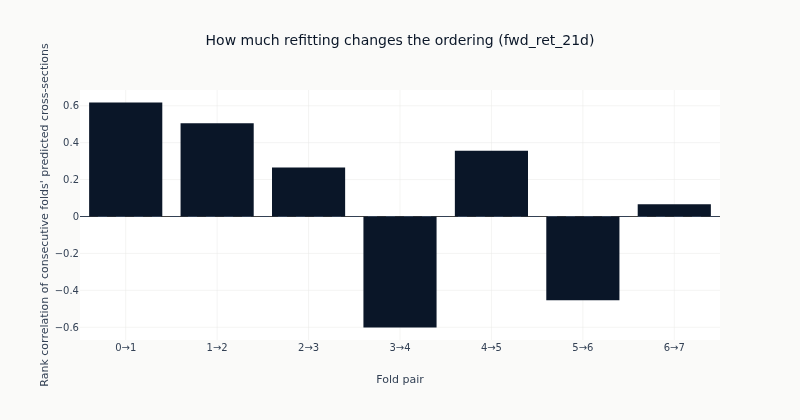

In [14]:
if turnover.height == 0:
    print(
        f"{len(folds)} fold(s) in this population, so there is no consecutive pair to compare "
        "and no turnover to chart."
    )
fig = go.Figure(
    go.Bar(
        x=turnover.get_column("fold_pair").to_list(),
        y=turnover.get_column("rank_correlation").to_list(),
        marker_color=COLORS["blue"],
        showlegend=False,
    )
)
fig.add_hline(y=0, line_width=1, line_dash="dash", line_color=COLORS["neutral"])
fig.update_yaxes(title_text="Rank correlation of consecutive folds' predicted cross-sections")
fig.update_xaxes(title_text="Fold pair")
fig.update_layout(
    title=f"How much refitting changes the ordering ({charted_label})",
    height=420,
    width=800,
    margin=dict(t=90),
)
# The range is read off the frame rather than asserted, so the alt text stays true of the next run.
_values = turnover.get_column("rank_correlation")
_range = (
    f"values from {_values.min():.2f} to {_values.max():.2f}"
    if turnover.height
    else "no fold pairs, so the chart is empty"
)
show_plotly_with_alt(
    fig,
    "Bar chart of the rank correlation between the predicted cross-sections of consecutive "
    "walk-forward folds, one bar per fold pair, with a dashed zero line. Counted from the frame: "
    f"{turnover.height} fold pairs, {_range}.",
)

### The eight folds behind each average

`ic_mean` above is the equal-weight mean of eight per-fold correlations, and section 5 argues
from how those eight are spread rather than from where they average. A run that reuses a
published fit prints nothing while fitting, so the fold rows are read back from the registry
here - the same rows the mean was taken over - and every per-fold number section 5 quotes comes
from this table.

`n_entities` is how many funds the fold **scored**, which is not the number it fitted on: the
training window reaches further back than the validation block and carries funds that have since
left the panel.

<!-- ML4T_ZH_BEGIN c0026-p000 -->
### 每個平均值背後的八折

上方 `ic_mean` 是八個逐折相關性的等權平均值，而第 5 節的論述依據的是八個數值如何分布，而非平均值的位置。重用已發布擬合結果時，執行過程不會印出內容，因此此處從登錄系統讀回逐折資料列，也就是計算平均值時使用的相同資料列；第 5 節引用的每個逐折數值都來自這張表。

`n_entities` 是該折**評分**的基金數量，並非擬合所用的基金數量：訓練視窗比驗證區塊往前延伸更久，包含後來已退出資料面板的基金。
<!-- ML4T_ZH_END c0026-p000 -->


In [15]:
folds_charted = charted.folds()
print(
    f"{charted_label}: {folds_charted.height} folds, "
    f"{folds_charted.filter(pl.col('ic') < 0).height} negative, "
    f"mean {folds_charted.get_column('ic').mean():+.4f}"
)
folds_charted

fwd_ret_21d: 8 folds, 6 negative, mean -0.0326


fold_id,ic,ic_std,n_entities
i64,f64,f64,f64
0,-0.051149,0.320668,77.0
1,-0.181914,0.223695,76.0
2,0.064832,0.192816,79.0
3,-0.10362,0.479211,82.0
4,0.115767,0.302743,86.0
5,-0.003361,0.175347,88.0
6,-0.025022,0.361048,88.0
7,-0.076172,0.330584,92.0


## 5. What to notice

**The forward-return panel's own covariance structure does not rank these funds.** On the primary
label the mean validation IC is **-0.033**, and on the five-day variant **+0.010**. Neither is
evidence of skill, and the negative one is not an inverted signal either: the eight fold ICs
behind it run -0.076, -0.025, -0.003, +0.116, -0.104, +0.065, -0.182, -0.051, so the sign changes
four times and the spread across folds is several times the size of the average. That is the
shape of a quantity centred on nothing.

**The ordering itself reverses when the model is refitted.** The rank correlation between
consecutive folds' predicted cross-sections is negative on two of the seven pairs (-0.45 and
-0.60) and above +0.5 on two others. A fund near the top of one fold's ranking is as likely to
be near the bottom of the next as to stay where it was. The sign ambiguity of a principal
component does not explain this - the premium is averaged from the same fitted factor returns
the loadings came from, so a flipped component flips both and cancels - which leaves the
ordering genuinely turning over as the training window rolls forward.


<!-- ML4T_ZH_BEGIN c0028-p000 -->
## 5. 值得注意的結果

**前瞻報酬率面板自身的共變異數結構，無法為這些基金有效排名。** 在主要標籤上，平均驗證 IC 為 **-0.033**；在五日版本上為 **+0.010**。兩者都不是預測能力的證據，而負值也不是反向訊號：其背後八折的 IC 依序為 -0.076、-0.025、-0.003、+0.116、-0.104、+0.065、-0.182、-0.051，符號變換了四次，跨折差異範圍是平均值的數倍。這是以零為中心的數值所呈現的形狀。

**模型重新擬合時，排序本身也會翻轉。** 相鄰折預測橫斷面的排名相關性，在七對中有兩對為負（-0.45 與 -0.60），另有兩對高於 +0.5。某折排名接近頂端的基金，在下一折接近底端的機率，與維持原位一樣高。主成分的符號不確定性無法解釋這點：因子溢酬是從產生負荷的同一次擬合之因子報酬率平均而得，因此若某個成分翻轉，兩者會一起翻轉並互相抵銷。剩下的解釋是，隨訓練視窗向前滾動，排序確實在改變。
<!-- ML4T_ZH_END c0028-p000 -->

**The daily IC has far fewer independent observations than `ic_n_days` suggests.** The check
above established that each fund holds one predicted value per fold, so across 1,995 validation
dates this model expresses **eight** rankings, not 1,995. Every date inside a fold is scoring the
same ordering against a different day of returns. `ic_std / sqrt(ic_n_days)` would therefore
understate the uncertainty on `ic_mean` by a wide margin, and that is why no such interval is
computed here. It is a property of any model whose forecast is constant within a fold, and it is
worth carrying into the notebooks that follow, where the forecast moves and the count means more.

**What this establishes for the rest of the family.** PCA is the member that reads none of the
71 feature columns, and it sets the bar the four conditioned members are measured against. That
bar is at zero. A conditioned member that ranks these funds materially better is being helped by
the conditioning rather than by the factor structure, which is the comparison
[`13_model_analysis`](13_model_analysis.ipynb) is arranged to make with every family in front of
it.


<!-- ML4T_ZH_BEGIN c0028-p001 -->
**每日 IC 的獨立觀測數，遠少於 `ic_n_days` 所暗示的數量。** 上述檢查證實，每檔基金在每折內只有一個預測值，因此在 1,995 個驗證日期中，此模型只表達了**八種**排名，而非 1,995 種。每折內的每個日期，都是將相同排序對照不同日期的報酬率評分。因此，`ic_std / sqrt(ic_n_days)` 會大幅低估 `ic_mean` 的不確定性，這也是此處不計算該類區間的原因。這是任何在同一折內預測固定不變的模型都具有的性質；閱讀後續 Notebook 時應記住這點，因為後續模型的預測會變動，計數也更有意義。

**這對此家族其餘模型確立了什麼。** PCA 是不讀取 71 個特徵欄位的成員，也是衡量另外四個條件式成員的門檻。這個門檻位於零。如果條件式成員能顯著改善這些基金的排名，幫助它的是條件資訊，而非單靠因子結構；[`13_model_analysis`](13_model_analysis.ipynb) 會在所有家族齊備後進行這項比較。
<!-- ML4T_ZH_END c0028-p001 -->

**Known limitations.** The matrix decomposed is the label's forward returns, and those overlap:
consecutive rows of the 21-day column share twenty of their twenty-one days. Much of the
covariance structure PCA finds is therefore that overlap rather than same-day co-movement, and
this is not the object a daily-return covariance matrix would be. It is the same target every
conditioned member of the family decomposes, which is what keeps the comparison in
[`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) a comparison about
conditioning rather than about the target. `n_factors` is declared rather than chosen, and
nothing here tests whether a different count would order the cross-section better - that would be
a search, and a search over validation IC is what this notebook is arranged to avoid. The
cross-section narrows as the window rolls forward - the `n_entities` column above falls from 92
funds on the first fold to 77 on the last - so the eight fold ICs are not eight readings of the
same experiment. And every number here is measured on validation folds that have been read many
times over by the time a case study reaches this notebook.

<!-- ML4T_ZH_BEGIN c0028-p002 -->
**已知限制。** 分解的矩陣是標籤的前瞻報酬率，而這些報酬率彼此重疊：21 日欄位的相鄰兩列，共享其中 20 個交易日。因此，PCA 找到的許多共變異數結構，來自期間重疊，而非同日共同變動；它與每日報酬率共變異數矩陣代表的對象不同。此家族每個條件式成員分解的也是同一目標，這讓 [`11c_conditional_autoencoder`](11c_conditional_autoencoder.ipynb) 中的比較聚焦於條件資訊，而非目標本身。`n_factors` 是預先宣告，而非經由選擇；此處沒有測試不同因子數是否能更好地排列橫斷面，因為那會成為一項搜尋，而本 Notebook 正是為避免依驗證 IC 搜尋而設計。隨視窗向前滾動，橫斷面逐漸縮小：上方 `n_entities` 欄從第一折的 92 檔基金降到最後一折的 77 檔，因此八個逐折 IC 並非相同實驗的八次讀數。此處每個數字都來自驗證折；到案例研究進入本 Notebook 時，這些折已被反覆查看多次。
<!-- ML4T_ZH_END c0028-p002 -->


**Next**: [`11b_ipca`](11b_ipca.ipynb) keeps the factor structure and drops the assumption that a
fund's exposure is a fixed number, letting the characteristics this notebook ignored set it
instead.

<!-- ML4T_ZH_BEGIN c0029-p000 -->
**下一步**：[`11b_ipca`](11b_ipca.ipynb) 保留因子結構，但不再假設基金曝險是固定數值，而讓本 Notebook 忽略的特徵決定曝險。
<!-- ML4T_ZH_END c0029-p000 -->
